In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    roc_curve,
    roc_auc_score,
    classification_report
)

In [2]:
df = pd.read_csv('diabetes.csv')

print(df.head())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   Pedigree  Age  Outcome  
0     0.627   50        1  
1     0.351   31        0  
2     0.672   32        1  
3     0.167   21        0  
4     2.288   33        1  


In [3]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")

df.info()

Dataset Shape: (768, 9)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Pregnancies    768 non-null    int64  
 1   Glucose        768 non-null    int64  
 2   BloodPressure  768 non-null    int64  
 3   SkinThickness  768 non-null    int64  
 4   Insulin        768 non-null    int64  
 5   BMI            768 non-null    float64
 6   Pedigree       768 non-null    float64
 7   Age            768 non-null    int64  
 8   Outcome        768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [4]:
print("Missing Values:")

print(df.isnull().sum())

print("\nZero Values:")

print((df == 0).sum())

Missing Values:
Pregnancies      0
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
Pedigree         0
Age              0
Outcome          0
dtype: int64

Zero Values:
Pregnancies      111
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
Pedigree           0
Age                0
Outcome          500
dtype: int64


In [5]:
cols = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

df[cols] = df[cols].replace(0, np.nan)

print("Missing Values After Replacing Zeros:")

print(df.isnull().sum())

Missing Values After Replacing Zeros:
Pregnancies        0
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
Pedigree           0
Age                0
Outcome            0
dtype: int64


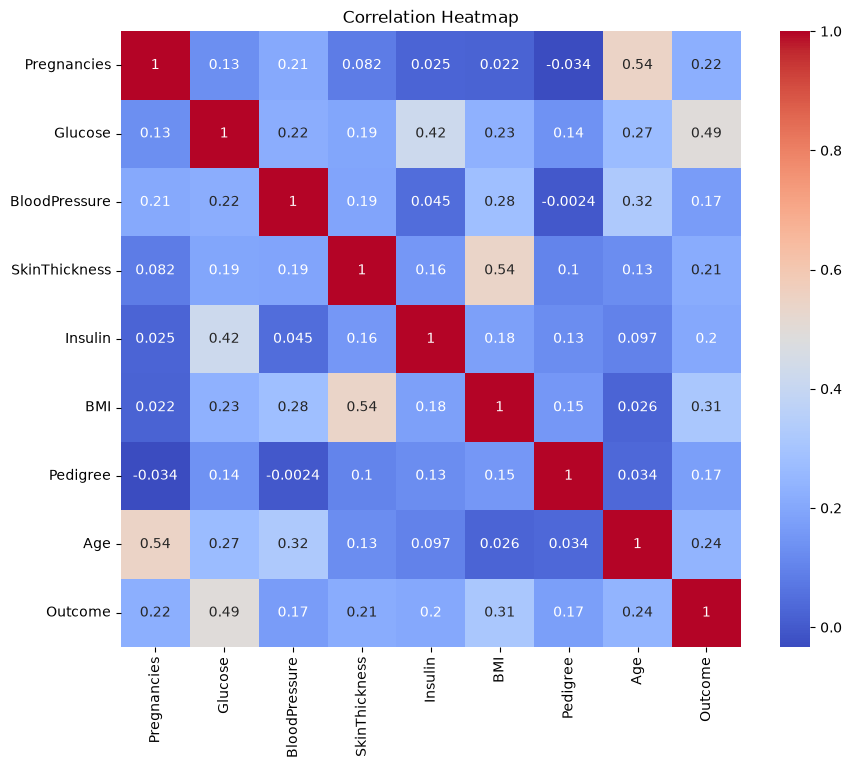

In [6]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    df.fillna(df.median(numeric_only=True)).corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")

plt.show()

In [7]:
X = df.drop('Outcome', axis=1)

y = df['Outcome']

print("Independent Variables Shape:", X.shape)

print("Dependent Variable Shape:", y.shape)

Independent Variables Shape: (768, 8)
Dependent Variable Shape: (768,)


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=1,
    stratify=y
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

Training Data: (614, 8)
Testing Data: (154, 8)


In [9]:
knn = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', KNeighborsClassifier(n_neighbors=5))
])

print("KNN Model Created Successfully")

KNN Model Created Successfully


In [10]:
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

print("First 10 Predictions:")

print(y_pred[:10])

First 10 Predictions:
[0 0 0 1 1 0 0 0 0 0]


Confusion Matrix:
[[82 18]
 [25 29]]


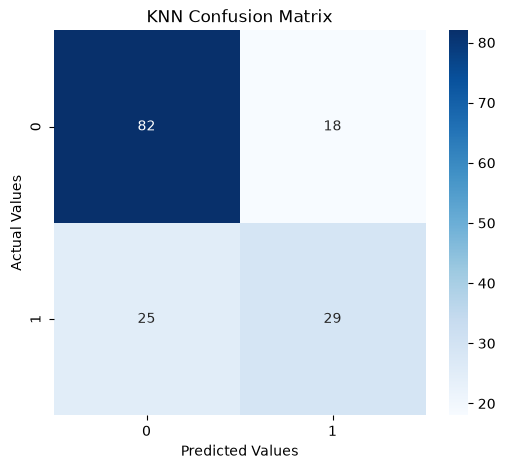

In [11]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")

print(cm)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted Values")

plt.ylabel("Actual Values")

plt.title("KNN Confusion Matrix")

plt.show()

In [12]:
accuracy = accuracy_score(y_test, y_pred)

error_rate = 1 - accuracy

precision = precision_score(y_test, y_pred, zero_division=0)

recall = recall_score(y_test, y_pred, zero_division=0)

print("Accuracy:", accuracy)

print("Accuracy Percentage:", accuracy * 100, "%")

print("Error Rate:", error_rate)

print("Error Rate Percentage:", error_rate * 100, "%")

print("Precision:", precision)

print("Recall:", recall)

Accuracy: 0.7207792207792207
Accuracy Percentage: 72.07792207792207 %
Error Rate: 0.27922077922077926
Error Rate Percentage: 27.922077922077925 %
Precision: 0.6170212765957447
Recall: 0.5370370370370371


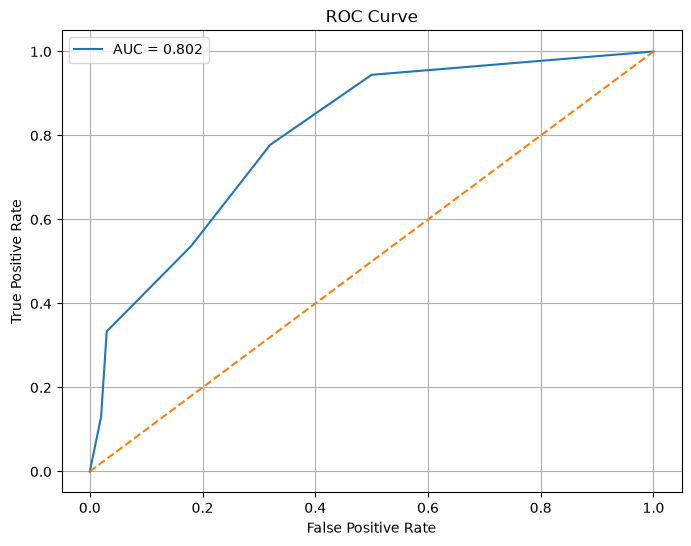

ROC AUC Score: 0.8020370370370371


In [13]:
y_prob = knn.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {auc_score:.3f}"
)

plt.plot([0, 1], [0, 1], '--')

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.grid()

plt.show()

print("ROC AUC Score:", auc_score)

In [14]:
print("Classification Report:")

print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.82      0.79       100
           1       0.62      0.54      0.57        54

    accuracy                           0.72       154
   macro avg       0.69      0.68      0.68       154
weighted avg       0.71      0.72      0.72       154

